# Gaussian Bayesian Classification

Реализация байесовского классификатора с гауссовскими распределениями классов на датасете Iris. Для визуализации используются два признака: длина и ширина лепестка.

Классификатор оценивает априорные вероятности, средние векторы и полные ковариационные матрицы для каждого класса. Для предсказания выбирается класс с максимальным произведением плотности и априорной вероятности.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from scipy.stats import multivariate_normal

## Реализация классификатора

In [2]:
class BayesClassifier:
  def __init__(self):
    self.classes_ = None
    self.priors_ = {}
    self.means_ = {}
    self.covariance_matrices_ = {}

  def fit(self, X, y):
    self.classes_ = np.unique(y)
    for c in self.classes_:
      Xc = X[y == c]
      self.priors_[c] = len(Xc) / len(X)
      self.means_[c] = Xc.mean(axis = 0)
      self.covariance_matrices_[c] = np.cov(Xc.T)
    return self

  def predict(self, X):
    predictions = []
    for x in X:
      scores = []
      for c in self.classes_:
        p_x_given_c = multivariate_normal.pdf(
            x,
            mean = self.means_[c],
            cov = self.covariance_matrices_[c]
        )
        score = p_x_given_c * self.priors_[c]
        scores.append(score)
      predictions.append(self.classes_[np.argmax(scores)])
    return np.array(predictions)

## 1. Подготовка данных

Разделение данных на обучающую (70%) и тестовую (30%) выборки с сохранением пропорций классов.

In [3]:
iris = load_iris()

X = iris.data
y = iris.target

feature_names = iris.feature_names
print(f'feature_names: {feature_names}')

class_names = iris.target_names
print(f'class_names: {class_names}')

feature_idx = [2, 3]
X = X[:, feature_idx]

print(f'X shape: {X.shape}')

feature_names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
class_names: ['setosa' 'versicolor' 'virginica']
X shape: (150, 2)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.3, random_state = 42, stratify = y
)

## 2. Гауссовские плотности классов

Линии уровня плотности для каждого класса на плоскости выбранных признаков. Параметры распределений оцениваются только на обучающей выборке.

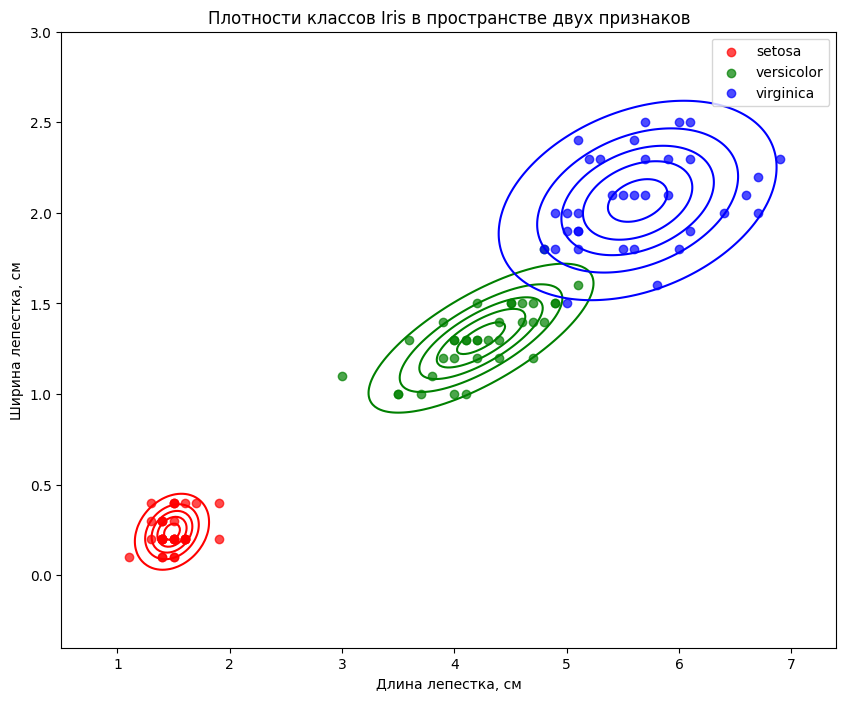

In [5]:
plt.figure(figsize=(10, 8))

class_colors = ['r', 'g', 'b']

x_left = X[:, 0].min() - 0.5
x_right = X[:, 0].max() + 0.5
y_bottom = X[:, 1].min() - 0.5
y_top = X[:, 1].max() + 0.5

x_grid, y_grid = np.meshgrid(
    np.linspace(x_left, x_right, 300),
    np.linspace(y_bottom, y_top, 300)
)

mesh_points = np.c_[x_grid.ravel(), y_grid.ravel()]

for class_id, class_color in zip(np.unique(y), class_colors):
    class_points = X_train[y_train == class_id]

    class_mean = class_points.mean(axis=0)
    class_cov = np.cov(class_points.T)

    distribution = multivariate_normal(
        mean=class_mean,
        cov=class_cov
    )

    density = distribution.pdf(mesh_points).reshape(x_grid.shape)

    contour_levels = np.linspace(
        0.1 * density.max(),
        0.9 * density.max(),
        5
    )

    plt.contour(
        x_grid,
        y_grid,
        density,
        colors=[class_color],
        levels=contour_levels
    )

    plt.scatter(
        class_points[:, 0],
        class_points[:, 1],
        color=class_color,
        alpha=0.7,
        label=class_names[class_id]
    )

plt.title("Плотности классов Iris в пространстве двух признаков")
plt.xlabel("Длина лепестка, см")
plt.ylabel("Ширина лепестка, см")
plt.legend()
plt.show()

**Вывод.** По длине и ширине лепестка класс Setosa хорошо отделяется от остальных. Распределения Versicolor и Virginica частично перекрываются, что может приводить к ошибкам классификации между этими классами.

## 3. Разделяющие границы

Области решений строятся с помощью собственной реализации классификатора.

In [6]:
model = BayesClassifier().fit(X_train, y_train)

In [7]:
Z = model.predict(mesh_points)
Z = Z.reshape(x_grid.shape)

In [8]:
from matplotlib.colors import ListedColormap

class_colors = ['darkorange', 'mediumorchid', 'seagreen']

decision_cmap = ListedColormap([
    '#FFD9A8',
    '#E4C8F5',
    '#BFE8D2'
])


def get_misclassified_points(X, y):
    predictions = model.predict(X)
    error_mask = predictions != y
    return X[error_mask]

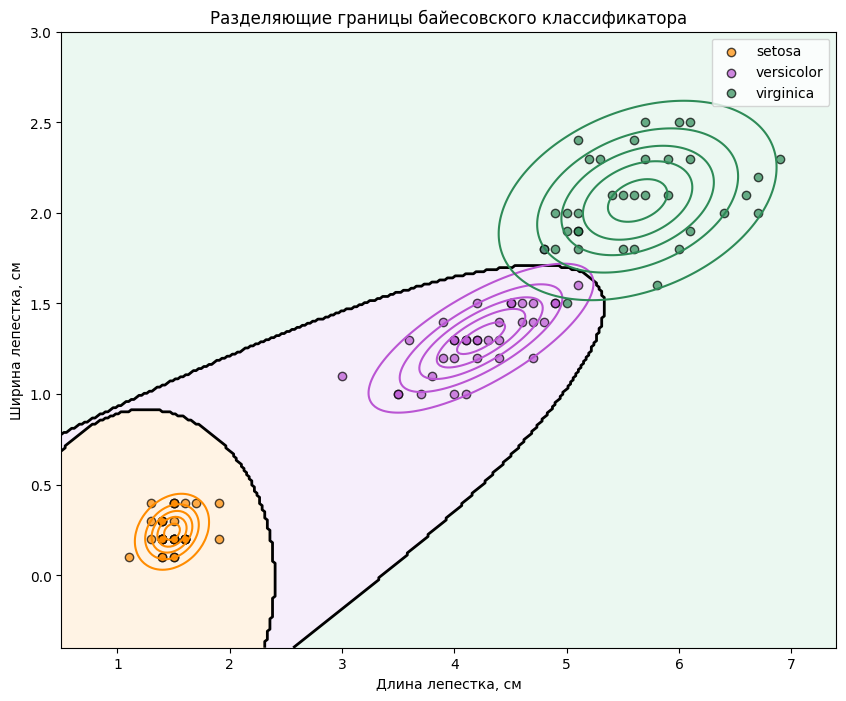

In [9]:
plt.figure(figsize=(10, 8))

plt.contourf(
    x_grid,
    y_grid,
    Z,
    alpha=0.3,
    cmap=decision_cmap
)

plt.contour(
    x_grid,
    y_grid,
    Z,
    levels=[0.5, 1.5],
    colors='black',
    linewidths=2
)

for class_id, class_color in zip(model.classes_, class_colors):

    class_points = X_train[y_train == class_id]

    class_mean = class_points.mean(axis=0)
    class_cov = np.cov(class_points.T)

    distribution = multivariate_normal(
        mean=class_mean,
        cov=class_cov
    )

    density = distribution.pdf(mesh_points).reshape(x_grid.shape)

    contour_levels = np.linspace(
        0.1 * density.max(),
        0.9 * density.max(),
        5
    )

    plt.contour(
        x_grid,
        y_grid,
        density,
        colors=[class_color],
        levels=contour_levels
    )

    plt.scatter(
        class_points[:, 0],
        class_points[:, 1],
        label=class_names[class_id],
        color=class_color,
        edgecolor='black',
        alpha=0.7
    )

plt.title("Разделяющие границы байесовского классификатора")
plt.xlabel("Длина лепестка, см")
plt.ylabel("Ширина лепестка, см")
plt.legend()
plt.show()

**Вывод.** Setosa имеет отдельную область классификации и хорошо отделяется от остальных классов. Граница между Versicolor и Virginica проходит в области их частичного перекрытия, поэтому различать эти классы сложнее.

## 4. Анализ ошибок

Ошибочно классифицированные объекты выделены на графиках обучающей и тестовой выборок.

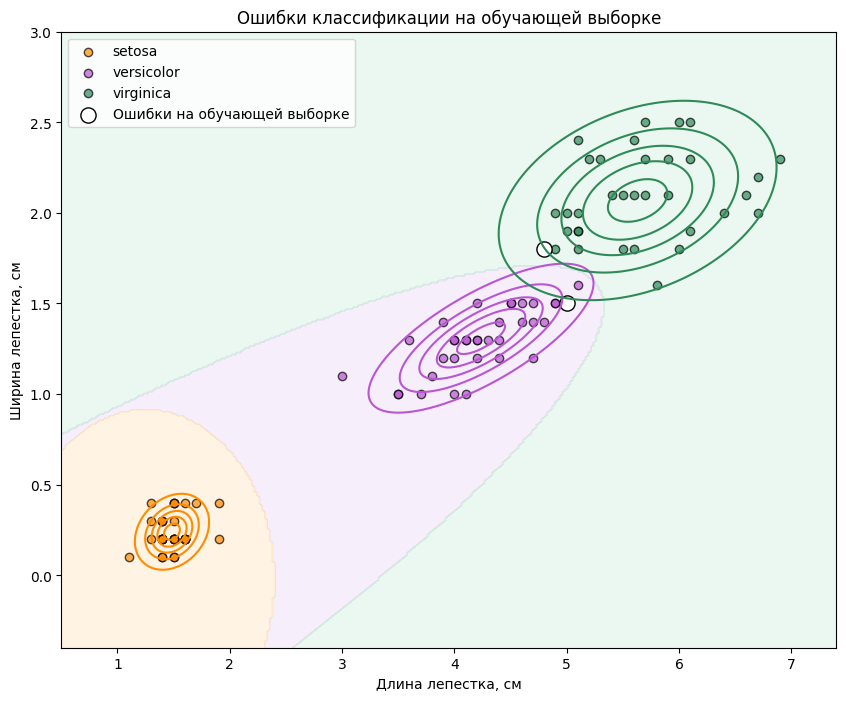

In [10]:
plt.figure(figsize=(10, 8))

plt.contourf(
    x_grid,
    y_grid,
    Z,
    alpha=0.3,
    cmap=decision_cmap
)

for class_id, class_color in zip(model.classes_, class_colors):

    class_points = X_train[y_train == class_id]

    class_mean = class_points.mean(axis=0)
    class_cov = np.cov(class_points.T)

    distribution = multivariate_normal(
        mean=class_mean,
        cov=class_cov
    )

    density = distribution.pdf(mesh_points).reshape(x_grid.shape)

    contour_levels = np.linspace(
        0.1 * density.max(),
        0.9 * density.max(),
        5
    )

    plt.contour(
        x_grid,
        y_grid,
        density,
        colors=[class_color],
        levels=contour_levels
    )

    plt.scatter(
        class_points[:, 0],
        class_points[:, 1],
        label=class_names[class_id],
        color=class_color,
        edgecolor='black',
        alpha=0.7
    )

train_errors = get_misclassified_points(X_train, y_train)

plt.scatter(
    train_errors[:, 0],
    train_errors[:, 1],
    facecolors='white',
    edgecolors='black',
    s=120,
    label='Ошибки на обучающей выборке'
)

plt.title("Ошибки классификации на обучающей выборке")
plt.xlabel("Длина лепестка, см")
plt.ylabel("Ширина лепестка, см")
plt.legend()
plt.show()

**Обучающая выборка.** Ошибки возникают между классами Versicolor и Virginica. Объекты Setosa классифицируются правильно.

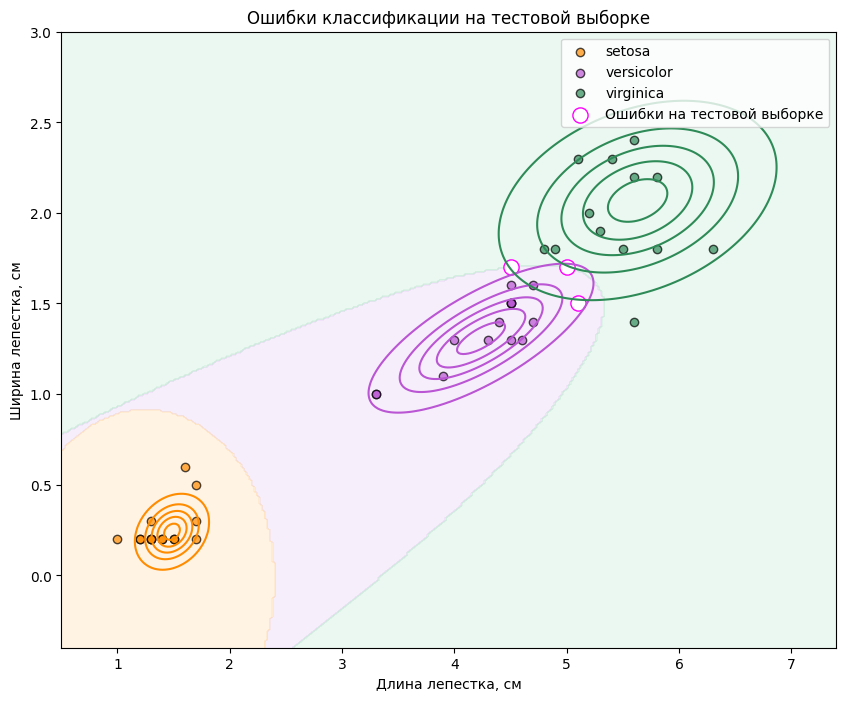

In [11]:
plt.figure(figsize=(10, 8))

plt.contourf(
    x_grid,
    y_grid,
    Z,
    alpha=0.3,
    cmap=decision_cmap
)

for class_id, class_color in zip(model.classes_, class_colors):

    test_class_points = X_test[y_test == class_id]

    class_mean = model.means_[class_id]
    class_cov = model.covariance_matrices_[class_id]

    distribution = multivariate_normal(
        mean=class_mean,
        cov=class_cov
    )

    density = distribution.pdf(mesh_points).reshape(x_grid.shape)

    contour_levels = np.linspace(
        0.1 * density.max(),
        0.9 * density.max(),
        5
    )

    plt.contour(
        x_grid,
        y_grid,
        density,
        colors=[class_color],
        levels=contour_levels
    )

    plt.scatter(
        test_class_points[:, 0],
        test_class_points[:, 1],
        label=class_names[class_id],
        color=class_color,
        edgecolor='black',
        alpha=0.7
    )

test_errors = get_misclassified_points(X_test, y_test)

plt.scatter(
    test_errors[:, 0],
    test_errors[:, 1],
    facecolors='white',
    edgecolors='magenta',
    s=120,
    label='Ошибки на тестовой выборке'
)

plt.title("Ошибки классификации на тестовой выборке")
plt.xlabel("Длина лепестка, см")
plt.ylabel("Ширина лепестка, см")
plt.legend()
plt.show()

**Тестовая выборка.** Наблюдаемые ошибки также связаны с перекрытием Versicolor и Virginica.

## 5. Метрики качества

Accuracy рассчитывается отдельно для обучающей и тестовой выборок. Значения относятся к одному стратифицированному разбиению Iris с random_state=42.

In [12]:
from sklearn.metrics import accuracy_score

train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Train accuracy: {train_accuracy:.2%} ({(train_predictions == y_train).sum()}/{len(y_train)})")
print(f"Test accuracy:  {test_accuracy:.2%} ({(test_predictions == y_test).sum()}/{len(y_test)})")

Train accuracy: 98.10% (103/105)
Test accuracy:  93.33% (42/45)


**Ограничение.** Iris - небольшой датасет, а тестовая выборка содержит 45 объектов. Результат одного разбиения не гарантирует такую же точность на других данных.